In [21]:
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.cluster import KMeans

In [22]:
INPUT_FOLDER = "./assets/final_tests2"
OUTPUT_FOLDER = "./assets/final_tests2_extracted"

NUM_SELECTED = 20
BATCH_SIZE = 32

IMAGE_SIZE = (224, 224)

RANDOM_STATE = 42

In [23]:
def get_image_paths(folder):

    extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp"
    }

    folder = Path(folder)

    paths = [
        path
        for path in folder.rglob("*")
        if path.suffix.lower() in extensions
    ]

    paths.sort()

    return paths


image_paths = get_image_paths(
    INPUT_FOLDER
)

print(
    f"Found {len(image_paths)} images"
)

if len(image_paths) < NUM_SELECTED:
    raise ValueError(
        "Number of images is smaller than ",NUM_SELECTED
    )

Found 180 images


In [24]:
def load_and_preprocess_image(path):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape(
        [None, None, 3]
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.keras.applications.resnet50.preprocess_input(
        image
    )

    return image


path_strings = [
    str(path)
    for path in image_paths
]

dataset = tf.data.Dataset.from_tensor_slices(
    path_strings
)

dataset = dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

dataset = dataset.batch(
    BATCH_SIZE
)

dataset = dataset.prefetch(
    tf.data.AUTOTUNE
)

In [25]:
print("\nLoading ResNet50...")

model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

model.trainable = False



Loading ResNet50...


In [26]:
print("\nGenerating embeddings...")

embeddings = model.predict(
    dataset,
    verbose=1
)

print(
    "Embedding shape:",
    embeddings.shape
)


Generating embeddings...
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step
Embedding shape: (180, 2048)


In [27]:
norms = np.linalg.norm(
    embeddings,
    axis=1,
    keepdims=True
)

normalized_embeddings = (
    embeddings / (norms + 1e-10)
)

In [28]:
print("\nRunning KMeans...")

kmeans = KMeans(
    n_clusters=NUM_SELECTED,
    random_state=RANDOM_STATE,
    n_init="auto"
)

cluster_labels = kmeans.fit_predict(
    normalized_embeddings
)

centroids = kmeans.cluster_centers_



Running KMeans...


In [29]:
selected_indices = []


for cluster_id in range(NUM_SELECTED):

    cluster_indices = np.where(
        cluster_labels == cluster_id
    )[0]

    cluster_embeddings = (
        normalized_embeddings[
            cluster_indices
        ]
    )

    centroid = centroids[
        cluster_id
    ]

    distances = np.linalg.norm(
        cluster_embeddings - centroid,
        axis=1
    )

    nearest_local_index = np.argmin(
        distances
    )

    nearest_global_index = (
        cluster_indices[
            nearest_local_index
        ]
    )

    selected_indices.append(
        nearest_global_index
    )


selected_indices = np.array(
    selected_indices
)

selected_paths = [
    image_paths[i]
    for i in selected_indices
]


print(
    "\nNumber selected:",
    len(selected_paths)
)



Number selected: 20


In [30]:
output_folder = Path(
    OUTPUT_FOLDER
)

output_folder.mkdir(
    parents=True,
    exist_ok=True
)


for i, source_path in enumerate(
    selected_paths
):

    destination_name = (
        f"{i:04d}_{source_path.name}"
    )

    destination = (
        output_folder /
        destination_name
    )

    shutil.copy2(
        source_path,
        destination
    )


print(
    f"Images saved to "
    f"{output_folder.resolve()}"
)

Images saved to /Users/oussamahabiballah/ensa/STAGE_CV/assets/final_tests2_extracted


In [31]:
import umap

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

embeddings_2d = reducer.fit_transform(embeddings)

/Users/oussamahabiballah/ensa/STAGE_CV/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


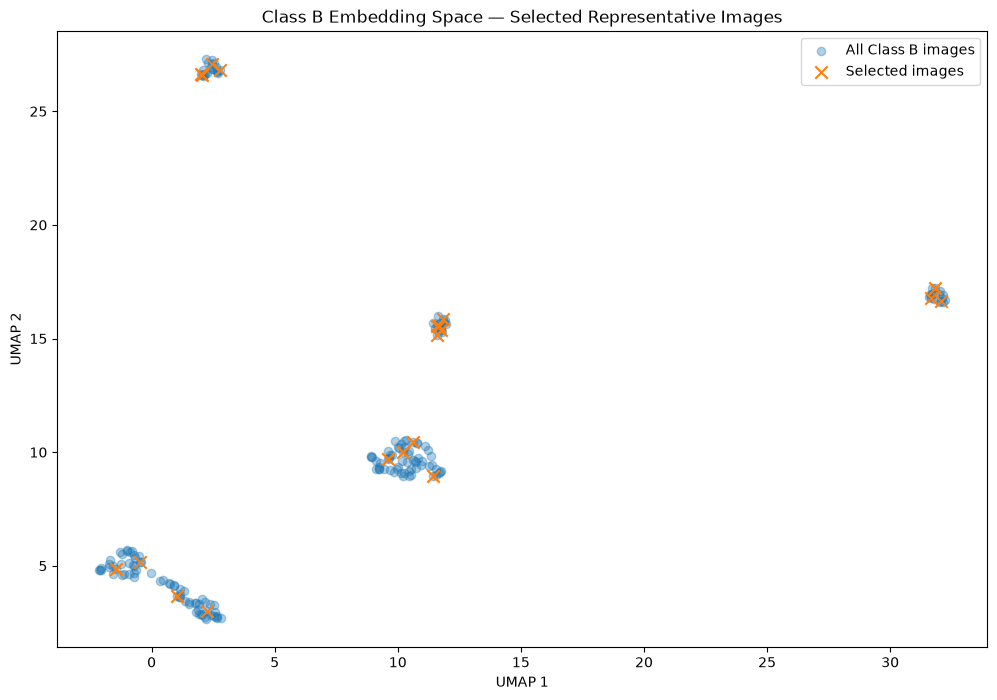

In [33]:
plt.figure(figsize=(12, 8))

plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    alpha=0.35,
    label="All Class B images"
)

plt.scatter(
    embeddings_2d[selected_indices, 0],
    embeddings_2d[selected_indices, 1],
    marker="x",
    s=80,
    label="Selected images"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Class B Embedding Space — Selected Representative Images")
plt.legend()
plt.show()